# 03 · Model Application, Evaluation & Error Analysis
Four classical classifiers × three feature sets. Hyper-parameters are tuned on the validation split (drawn from training only); each configuration is refit on train+val and scored **once** on the official test set.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src.config import *
from src.data_loader import load_raw, to_unit, make_splits
from src.plotting import set_style
set_style()
def show(name, w=900): display(Image(filename=str(FIG_DIR / f'{name}.png'), width=w))
from src import analysis as A
S = make_splits(); runs = A.load_runs(); df = pd.read_csv(TABLE_DIR/'model_results.csv')

## 1. Leaderboard

In [2]:
df.sort_values('accuracy', ascending=False)[['model','features','dim','val_acc','accuracy','macro_f1','fit_seconds','infer_ms_per_image','feat_ms_per_image','params','best_params']]

,model,features,dim,val_acc,accuracy,macro_f1,fit_seconds,infer_ms_per_image,feat_ms_per_image,params,best_params
11,SVM-RBF,hog_stats,880,0.900833,0.9137,0.913703,222.7,5.282961,0.179063,17548905,"{""C"": 5.0}"
7,SVM-RBF,hog,864,0.899000,0.9130,0.912994,206.6,5.358606,0.470427,18094716,"{""C"": 5.0}"
3,SVM-RBF,pixels,784,0.888750,0.8988,0.898515,192.2,4.526644,0.000156,14975057,"{""C"": 5.0}"
8,LogReg,hog_stats,880,0.896250,0.8894,0.888977,7.8,0.001309,0.179063,8810,"{""C"": 0.01}"
4,LogReg,hog,864,0.891250,0.8852,0.884812,6.1,0.001393,0.470427,8650,"{""C"": 0.01}"
10,RandomForest,hog_stats,880,0.884833,0.8821,0.881099,41.3,0.040846,0.179063,2509172,"{""n_estimators"": 300, ""max_depth"": null, ""min_..."
6,RandomForest,hog,864,0.882333,0.8781,0.876942,39.5,0.041863,0.470427,3233386,"{""n_estimators"": 300, ""max_depth"": null, ""min_..."
9,kNN,hog_stats,880,0.882583,0.8776,0.877977,0.0,0.313453,0.179063,52800000,"{""k"": 5, ""weights"": ""distance""}"
5,kNN,hog,864,0.882083,0.8774,0.877708,0.0,0.270516,0.470427,51840000,"{""k"": 5, ""weights"": ""distance""}"
2,RandomForest,pixels,784,0.886167,0.8760,0.874597,22.8,0.037263,0.000156,2542500,"{""n_estimators"": 300, ""max_depth"": 20, ""min_sa..."


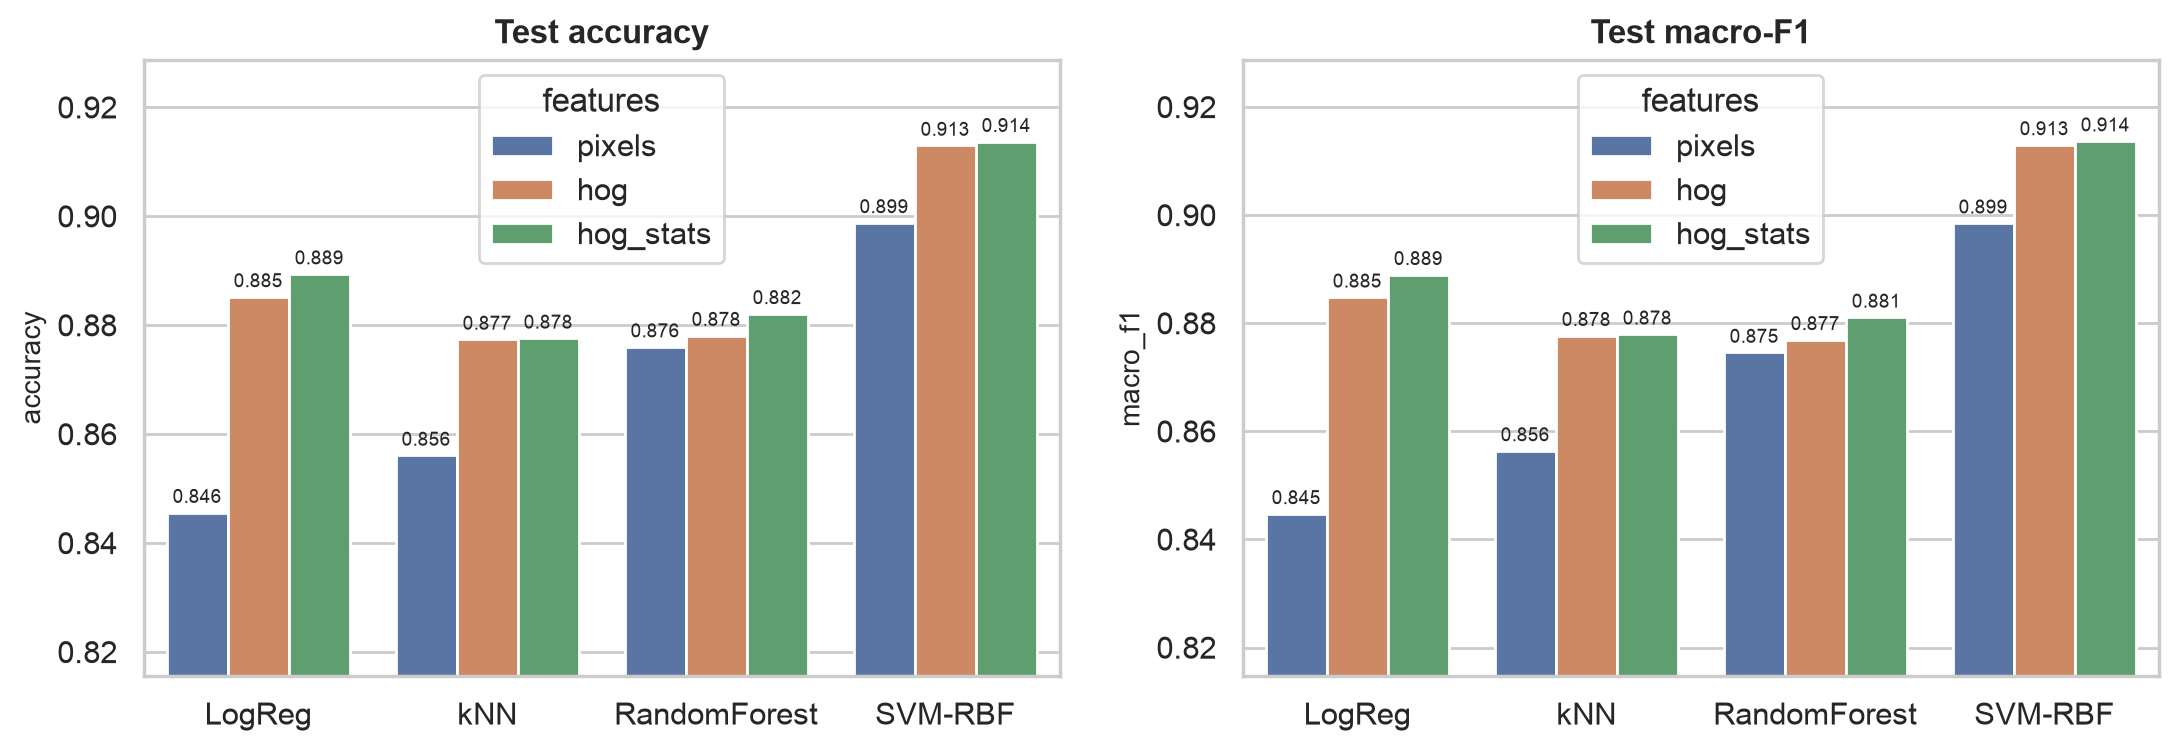

In [3]:
show('res_01_accuracy_f1_overview', 1000)

## 2. Cost: accuracy vs inference time and model size

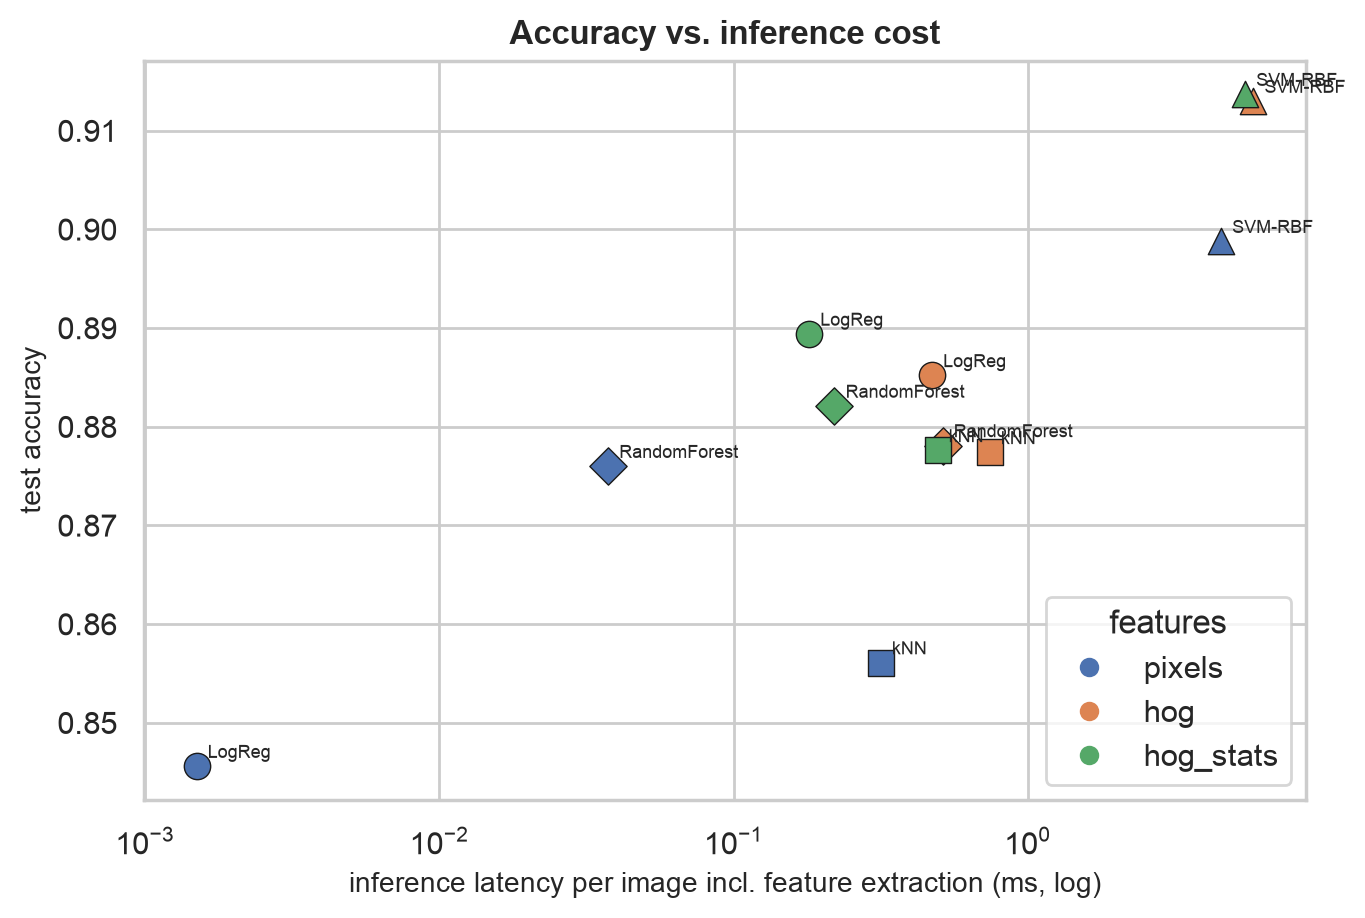

In [4]:
show('res_07_accuracy_vs_latency', 650)

## 3. Data efficiency

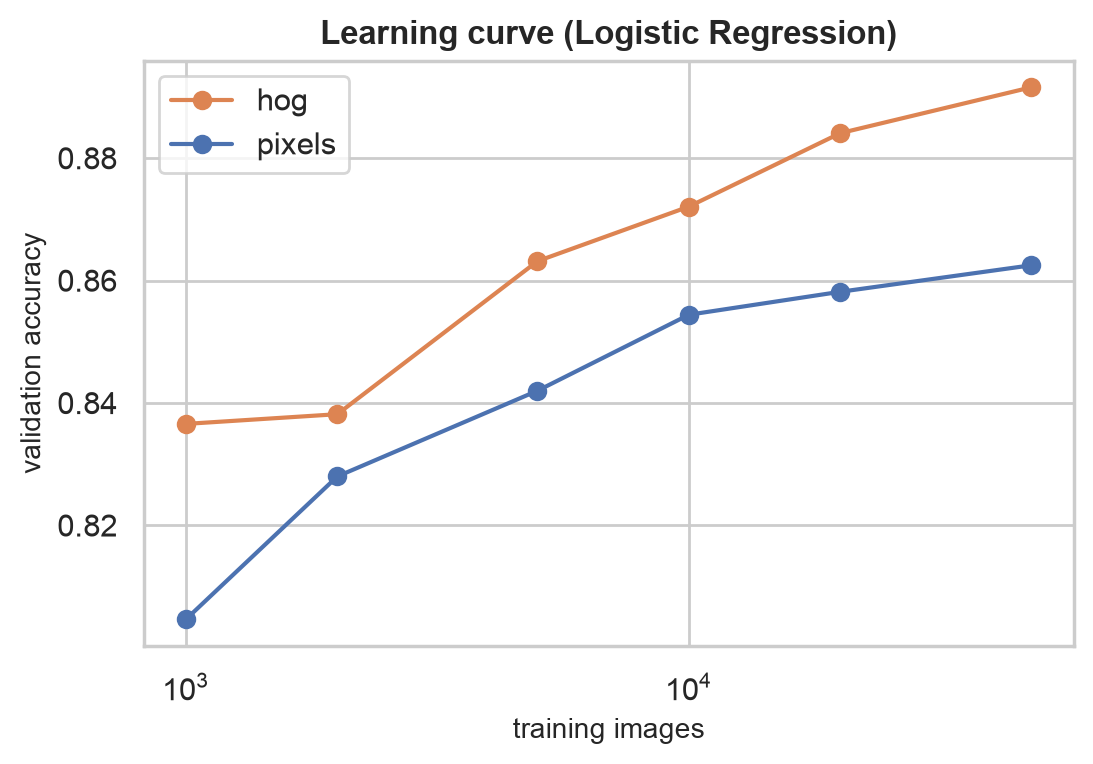

In [5]:
show('res_08_learning_curve', 520)

## 4. Per-class recall

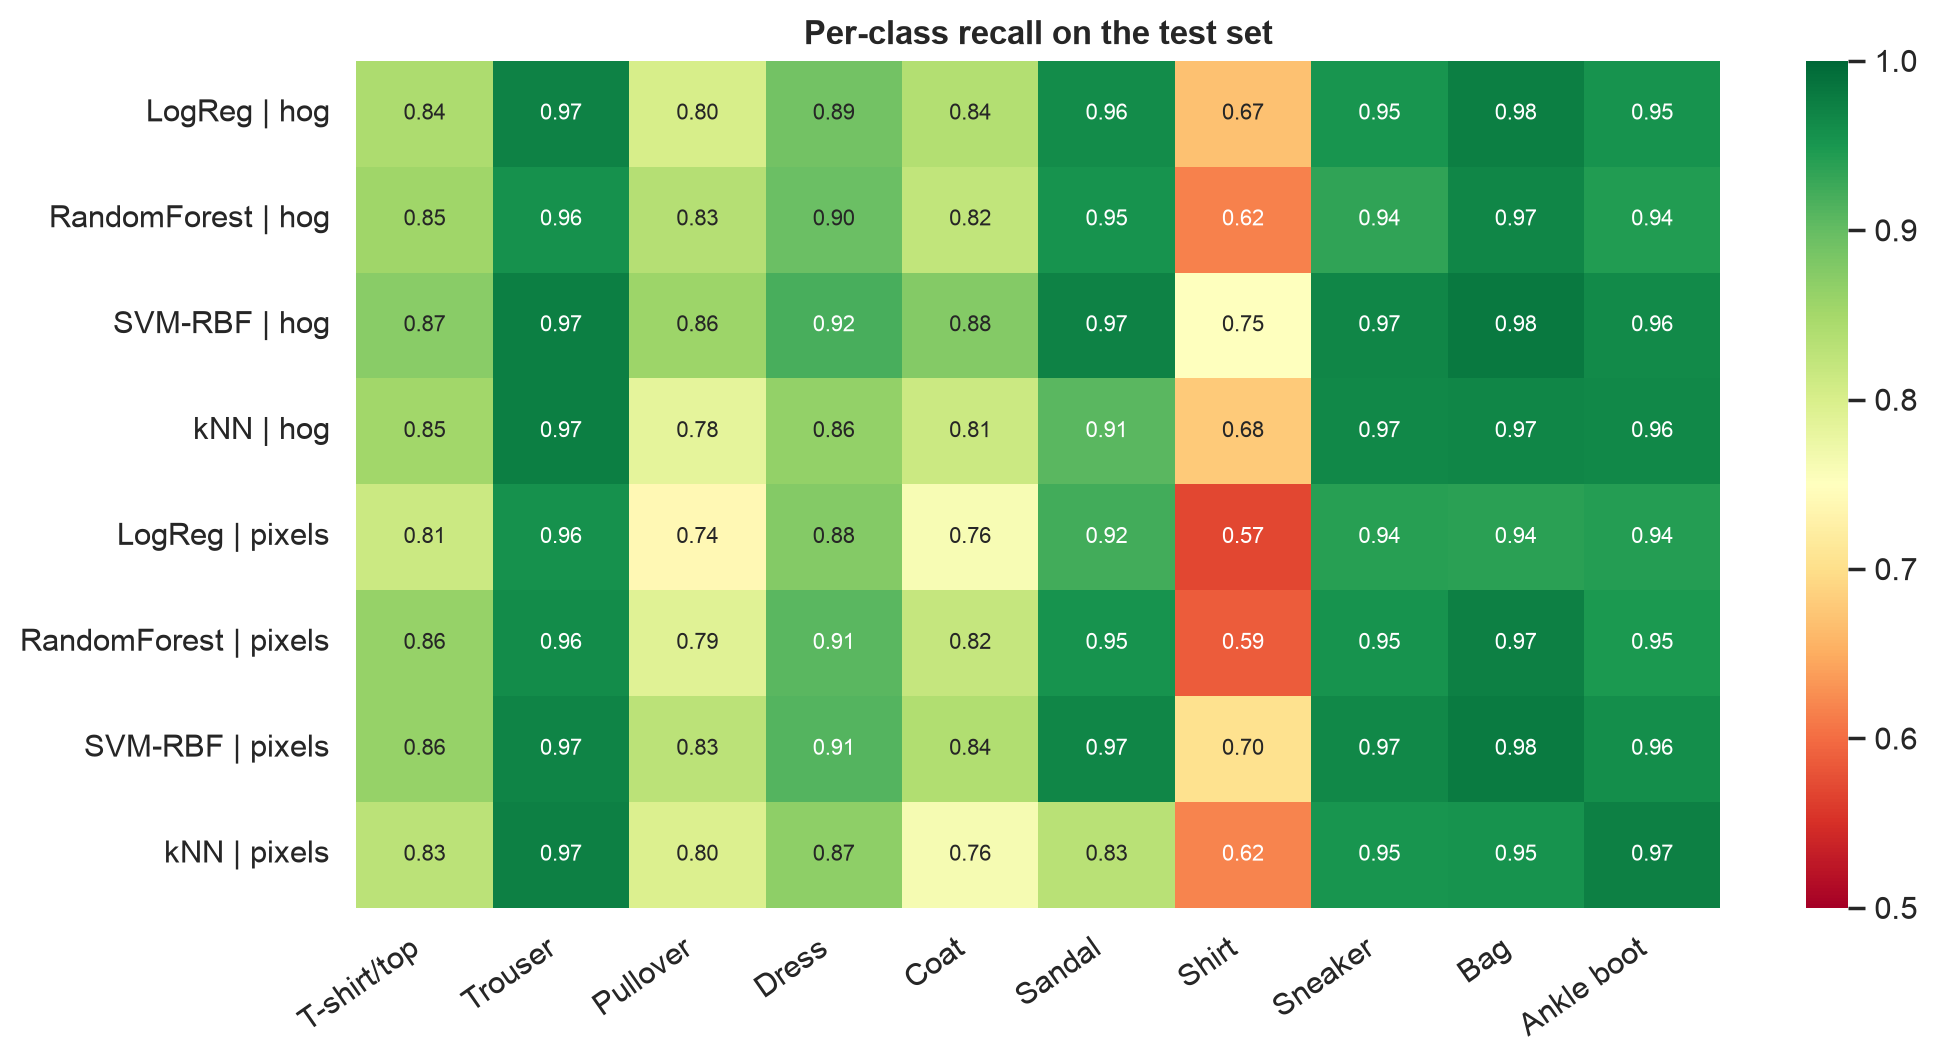

In [6]:
show('res_02_per_class_recall', 950)

## 5. Confusion matrices: best pixel model vs best HOG model

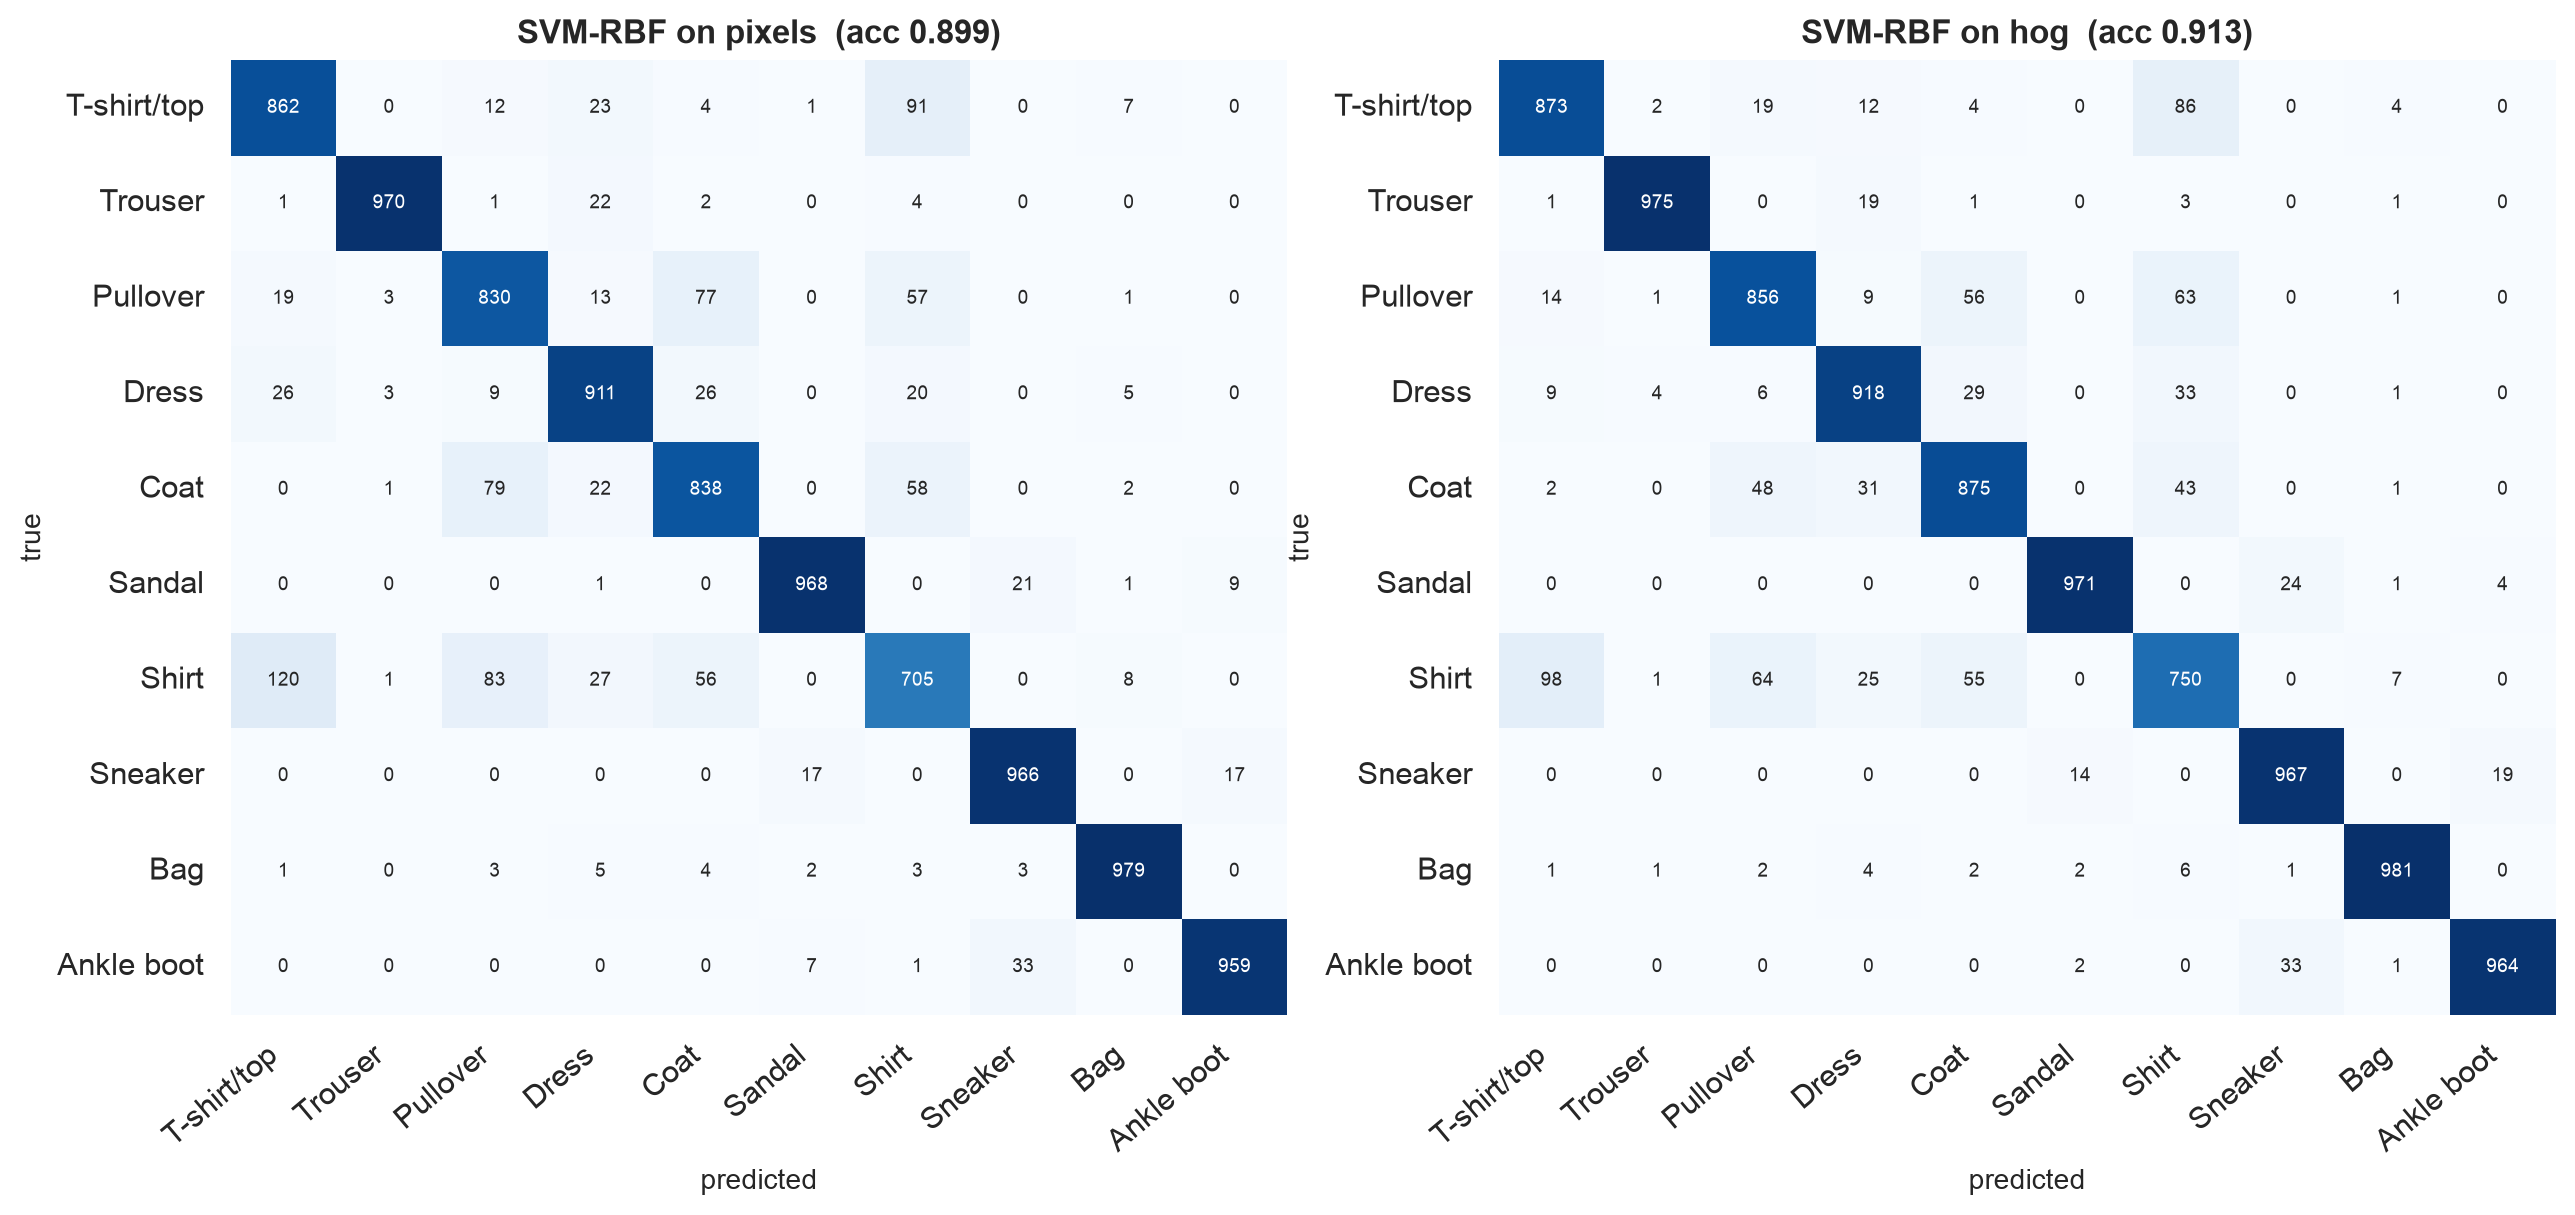

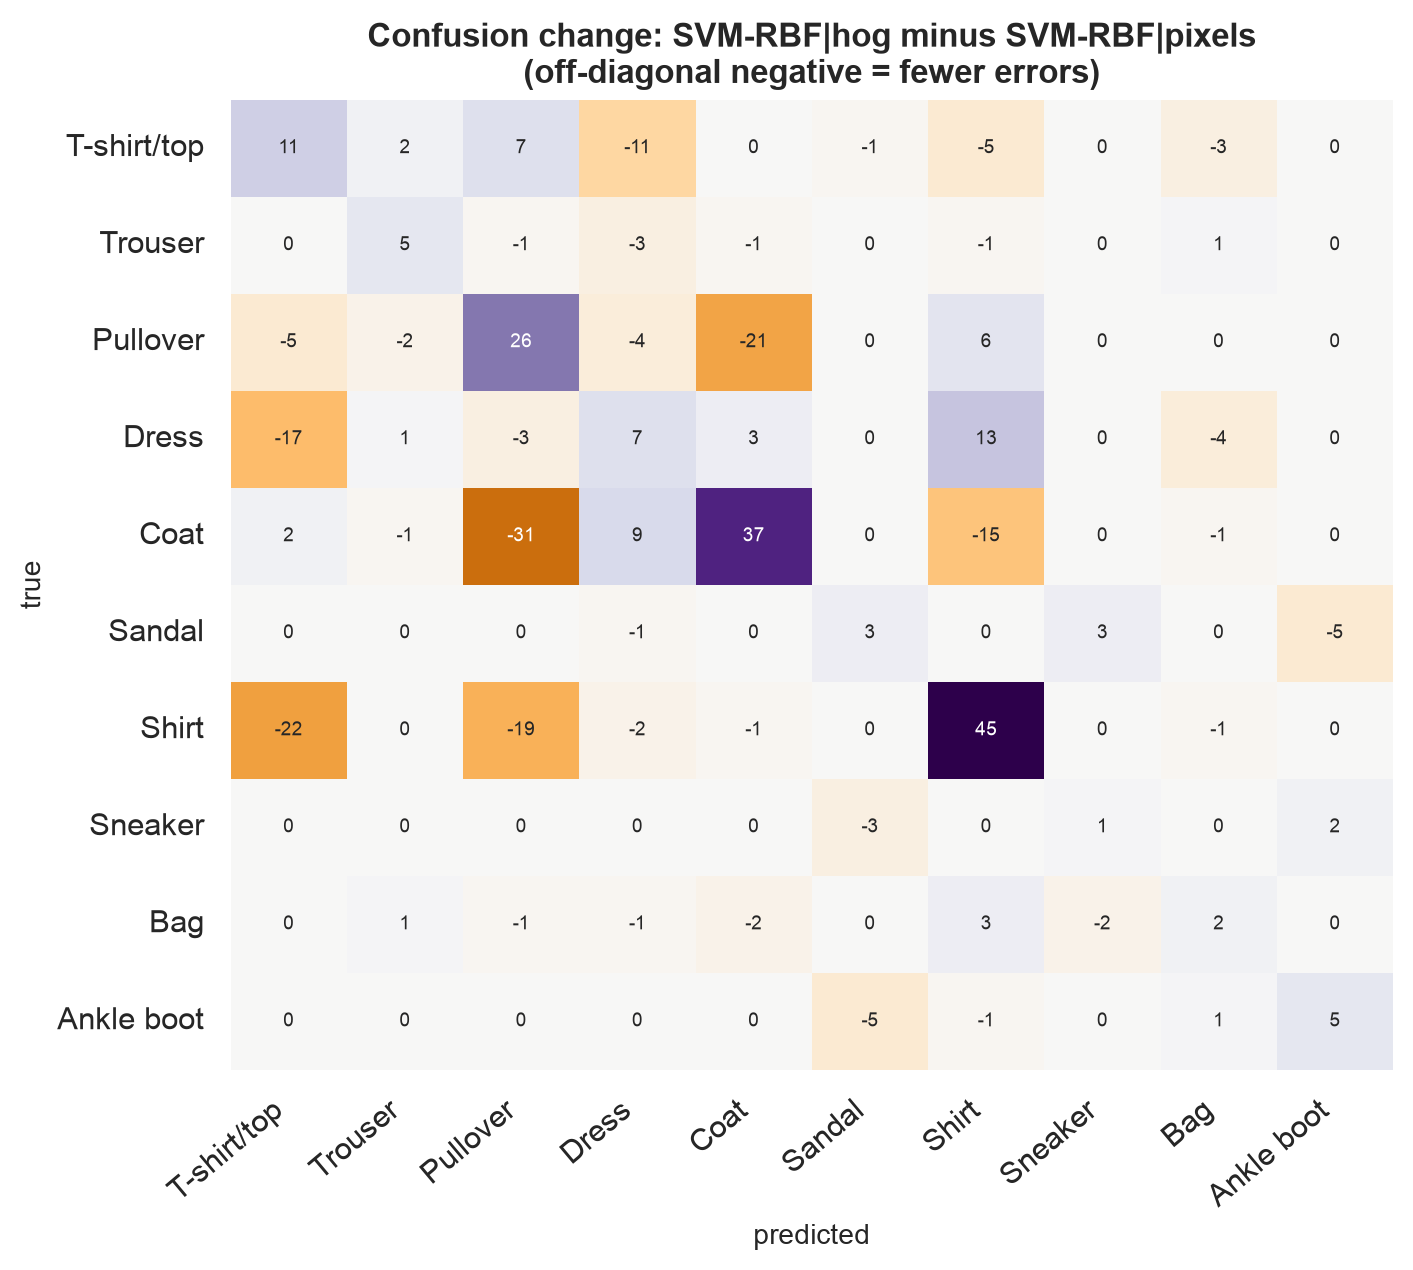

In [7]:
show('res_03_confusion_best_pixels_vs_best_hog', 1100); show('res_04_confusion_difference', 600)

## 6. Upper-body group (Shirt / T-shirt / Pullover / Coat)

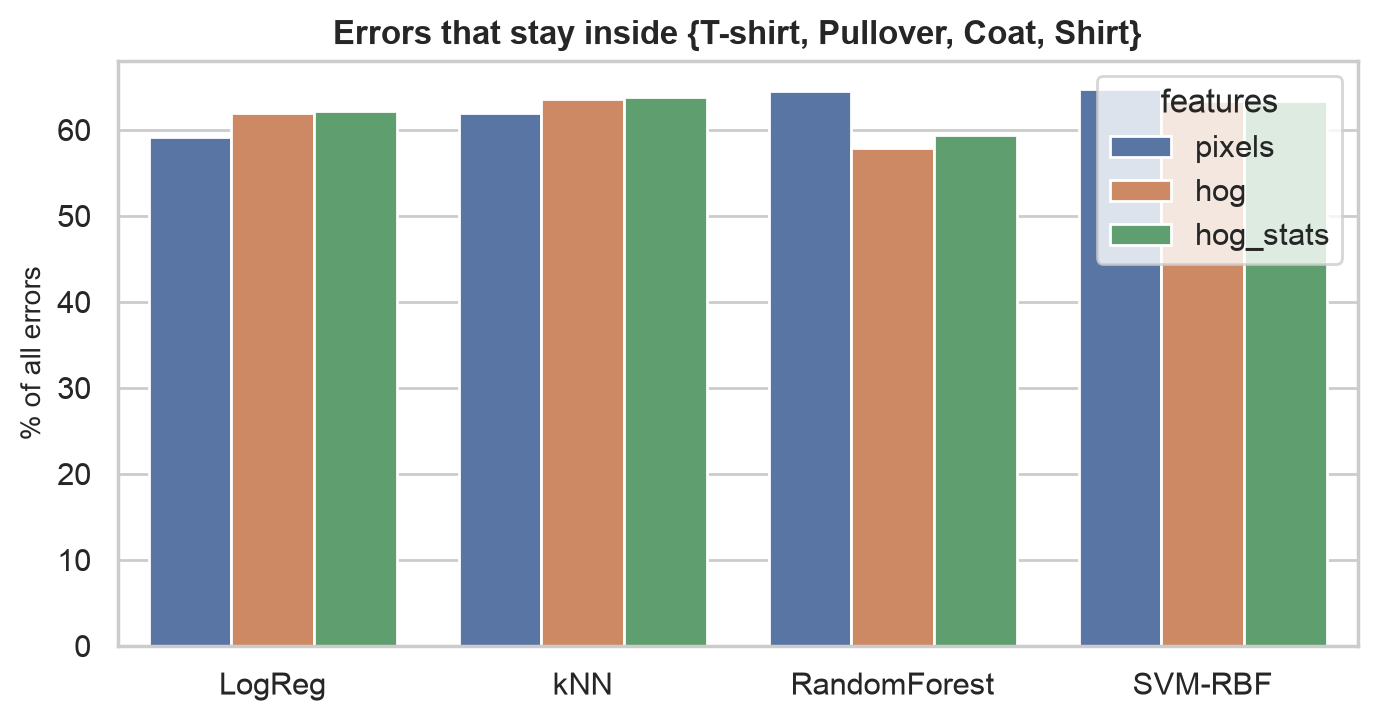

,model,features,errors,upper_body_confusions,share_pct
0,LogReg,hog,1148,712,62.0
1,RandomForest,hog,1219,706,57.9
2,SVM-RBF,hog,870,552,63.4
3,kNN,hog,1226,780,63.6
4,LogReg,hog_stats,1106,688,62.2
5,RandomForest,hog_stats,1179,700,59.4
6,SVM-RBF,hog_stats,863,547,63.4
7,kNN,hog_stats,1224,781,63.8
8,LogReg,pixels,1544,914,59.2
9,RandomForest,pixels,1240,800,64.5


In [8]:
show('res_05_upper_body_error_share', 600); pd.read_csv(TABLE_DIR/'upper_body_error_share.csv')

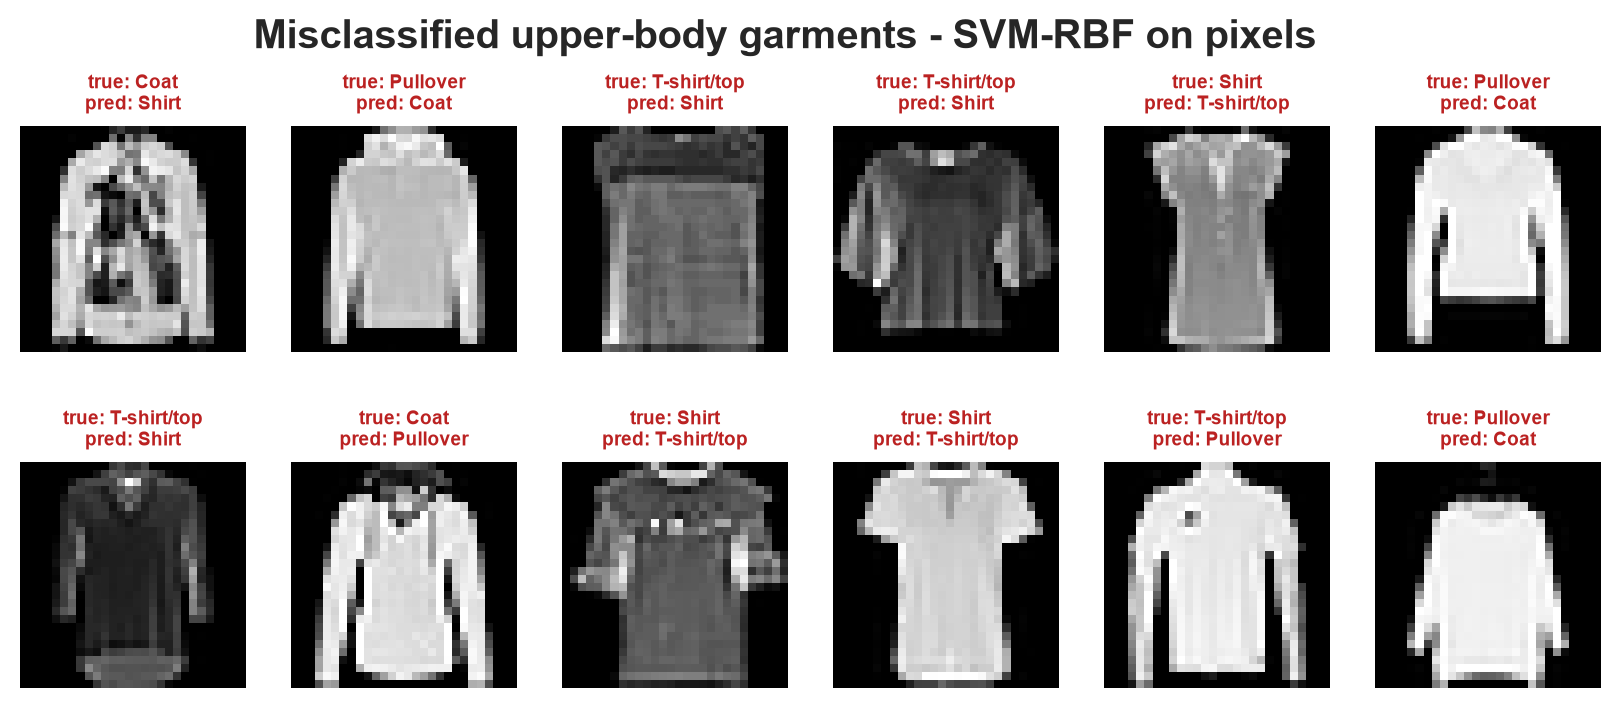

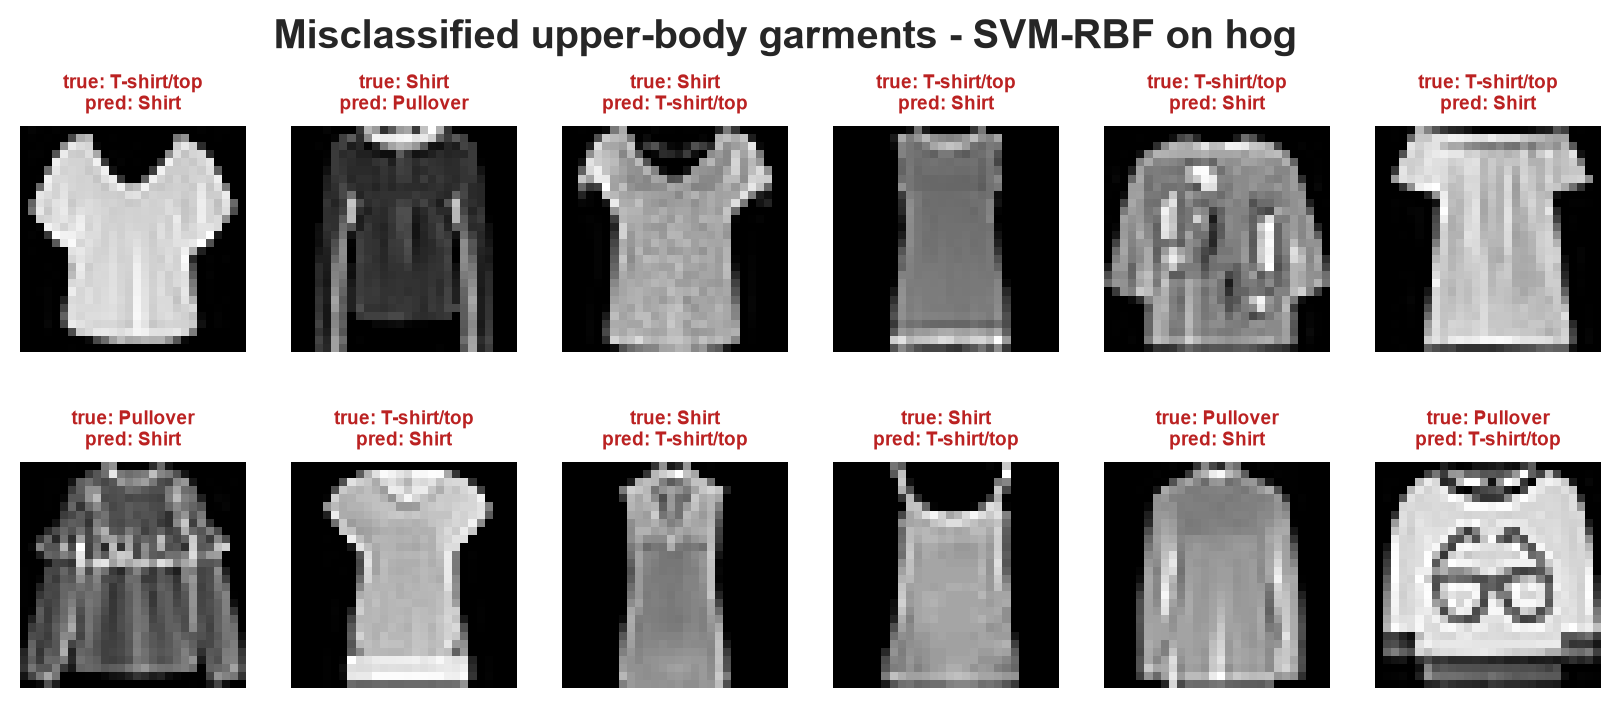

In [9]:
show('res_06a_misclassified_best_pixels', 800); show('res_06b_misclassified_best_hog', 800)

## 7. Statistical validation

In [10]:
pd.read_csv(TABLE_DIR/'mcnemar_pixels_vs_hog.csv')

,model,acc_pixels,acc_hog,delta,only_first_correct,only_second_correct,chi2,p_value
0,LogReg,0.8456,0.8852,0.0396,411,807,128.099343,0.000000e+00
1,kNN,0.8561,0.8774,0.0213,515,728,36.157683,1.819796e-09
2,RandomForest,0.8760,0.8781,0.0021,404,425,0.482509,4.872880e-01
3,SVM-RBF,0.8988,0.9130,0.0142,345,487,23.895433,1.017128e-06


In [11]:
pd.read_csv(TABLE_DIR/'bootstrap_ci.csv')

,model,features,accuracy,ci_low,ci_high
0,SVM-RBF,hog_stats,0.9137,0.908400,0.919100
1,SVM-RBF,hog,0.9130,0.907600,0.918500
2,SVM-RBF,pixels,0.8988,0.893100,0.904502
3,LogReg,hog_stats,0.8894,0.883200,0.895003
4,LogReg,hog,0.8852,0.879397,0.890800
5,RandomForest,hog_stats,0.8821,0.875598,0.888600
6,RandomForest,hog,0.8781,0.871500,0.884500
7,kNN,hog_stats,0.8776,0.871200,0.883800
8,kNN,hog,0.8774,0.871200,0.883800
9,RandomForest,pixels,0.8760,0.869800,0.882300


## 8. Largest confusions per model

In [12]:
pd.read_csv(TABLE_DIR/'top_confusions_all.csv').query('features=="hog"').head(12)

,model,features,true,predicted,count
10,LogReg,hog,Shirt,T-shirt/top,123
11,LogReg,hog,T-shirt/top,Shirt,98
12,LogReg,hog,Pullover,Coat,86
13,LogReg,hog,Shirt,Coat,84
14,LogReg,hog,Pullover,Shirt,84
15,LogReg,hog,Shirt,Pullover,76
16,LogReg,hog,Coat,Shirt,64
17,LogReg,hog,Coat,Pullover,51
18,LogReg,hog,Coat,Dress,40
19,LogReg,hog,Shirt,Dress,37
